<center><h1>Zambrano_Claudia_HW8</h1></center>

Name: Claudia Zambrano
<br>
Github Username: claudia-z712
<br>
USC ID: 8224948861

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)
import warnings
from sklearn.exceptions import ConvergenceWarning

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [3]:
# Features from the names dataset
features = [
    'radius', 'texture', 'perimeter', 'area', 'smoothness',
    'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension']

# Naming the rest of the columns
column_names = ['ID', 'Diagnosis']
for stat in ['mean', 'se', 'worst']:
    for feature in features:
        column_names.append(f"{feature}_{stat}")

# Adding the column names
df = pd.read_csv('wdbc.data', header=None, names=column_names)

# Identify all feature columns (excluding 'ID' and 'Diagnosis')
feature_cols = [col for col in df.columns if col not in ['ID', 'Diagnosis']]
scaler = StandardScaler()
df[feature_cols] = scaler.fit_transform(df[feature_cols])

# Convert into binary M=1 & B=0
df['Diagnosis'] = df['Diagnosis'].map({'M': 1, 'B': 0})

# Split so test data has 20% of Diagnosis = 1 and 20% of Diagnosis = 0 (stratified split)
df_train, df_test = train_test_split(df, test_size=0.2, 
                                     stratify=df['Diagnosis'],
                                     random_state=7)

print(f"Training set size: {len(df_train)}")
print(f"Testing set size: {len(df_test)}")
print("\nTest set class distribution:")
print(df_test['Diagnosis'].value_counts())


Training set size: 455
Testing set size: 114

Test set class distribution:
Diagnosis
0    72
1    42
Name: count, dtype: int64


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

,Metric,Train Average,Test Average
0,Accuracy,0.986989,0.967018
1,Precision,0.992094,0.973955
2,Recall,0.972941,0.936190
3,F1-Score,0.982407,0.954274
4,AUC,0.997657,0.992103


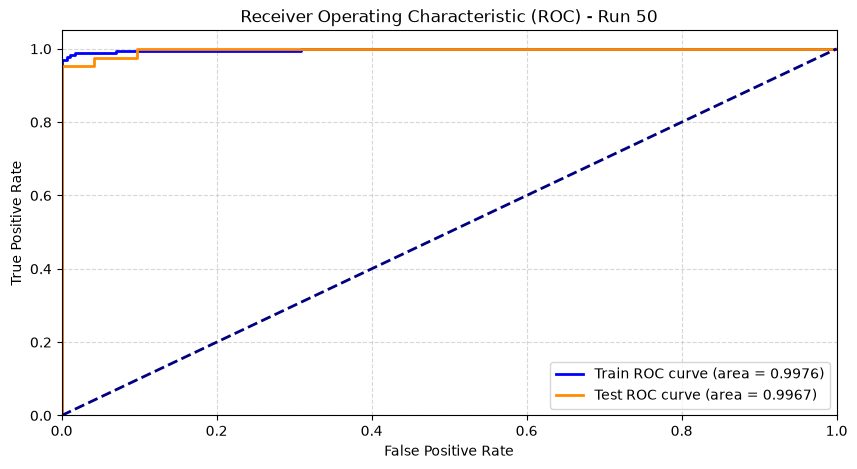

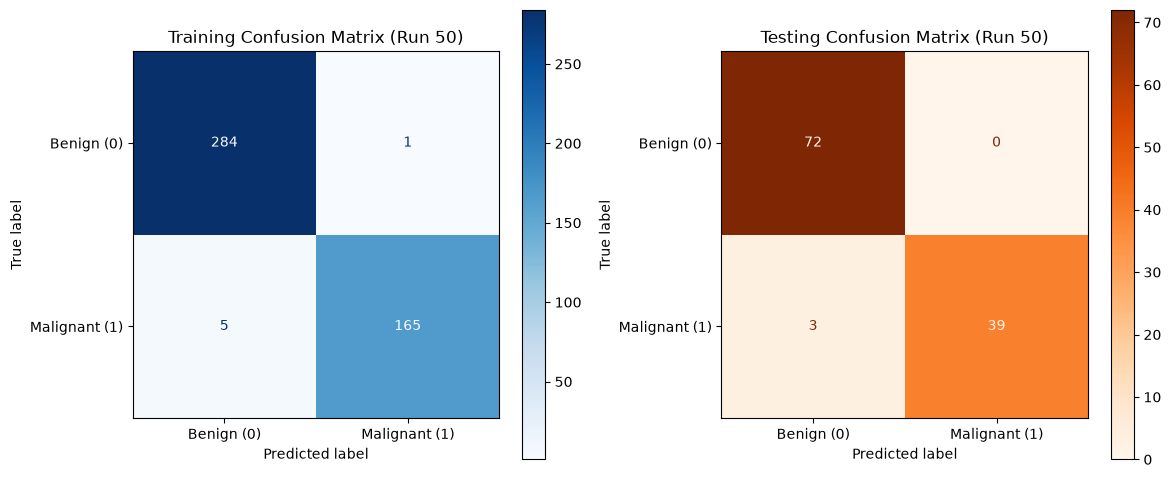

In [17]:
# Suppress convergence warnings during simulation to keep output clean
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Initialize lists to store metrics for 50 runs
train_metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}
test_metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}
 
# Data was standardized globally in the previous cell
# but will use the pipeline to ensure proper validation hygiene.
feature_cols = [col for col in df.columns if col not in ['ID', 'Diagnosis']]
X = df[feature_cols]
y = df['Diagnosis']

for run in range(1, 51):
    # 1. Split data (80% train, 20% test, stratified by Diagnosis)
    X_train_run, X_test_run, y_train_run, y_test_run = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=run
    )
    
    # 2. Define the pipeline with Scaling and L1-penalized LinearSVC
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', LinearSVC(penalty='l1', dual=False, random_state=run, max_iter=10000))
    ])
    
    # 3. Grid Search to find the best penalty parameter C
    parameters = {'svm__C': [0.001, 0.01, 0.1, 1, 10, 100]}
    clf = GridSearchCV(pipe, parameters, cv=5, scoring='accuracy')
    clf.fit(X_train_run, y_train_run)
    
    # 4. Predict on training and testing sets
    y_train_pred = clf.predict(X_train_run)
    y_test_pred = clf.predict(X_test_run)
    
    # For AUC, use decision function values as prediction scores
    y_train_scores = clf.decision_function(X_train_run)
    y_test_scores = clf.decision_function(X_test_run)
    
    # 5. Compute TRAIN Metrics
    train_metrics['accuracy'].append(accuracy_score(y_train_run, y_train_pred))
    train_metrics['precision'].append(precision_score(y_train_run, y_train_pred, zero_division=0))
    train_metrics['recall'].append(recall_score(y_train_run, y_train_pred))
    train_metrics['f1'].append(f1_score(y_train_run, y_train_pred))
    train_metrics['auc'].append(roc_auc_score(y_train_run, y_train_scores))
    
    # 6. Compute TEST Metrics
    test_metrics['accuracy'].append(accuracy_score(y_test_run, y_test_pred))
    test_metrics['precision'].append(precision_score(y_test_run, y_test_pred, zero_division=0))
    test_metrics['recall'].append(recall_score(y_test_run, y_test_pred))
    test_metrics['f1'].append(f1_score(y_test_run, y_test_pred))
    test_metrics['auc'].append(roc_auc_score(y_test_run, y_test_scores))

# Summary DataFrame for average metrics
summary_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC'],
    'Train Average': [
        np.mean(train_metrics['accuracy']),
        np.mean(train_metrics['precision']),
        np.mean(train_metrics['recall']),
        np.mean(train_metrics['f1']),
        np.mean(train_metrics['auc'])
    ],
    'Test Average': [
        np.mean(test_metrics['accuracy']),
        np.mean(test_metrics['precision']),
        np.mean(test_metrics['recall']),
        np.mean(test_metrics['f1']),
        np.mean(test_metrics['auc'])
    ]
}

summary_df = pd.DataFrame(summary_data)
display(summary_df)

# ROC
fpr_train, tpr_train, _ = roc_curve(y_train_run, y_train_scores)
roc_auc_train = auc(fpr_train, tpr_train)

fpr_test, tpr_test, _ = roc_curve(y_test_run, y_test_scores)
roc_auc_test = auc(fpr_test, tpr_test)

# Plot ROC Curves
plt.figure(figsize=(10, 5))
plt.plot(fpr_train, tpr_train, color='blue', lw=2, label=f'Train ROC curve (area = {roc_auc_train:.4f})')
plt.plot(fpr_test, tpr_test, color='darkorange', lw=2, label=f'Test ROC curve (area = {roc_auc_test:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - Run 50')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Confusion Matrices
cm_train = confusion_matrix(y_train_run, y_train_pred)
cm_test = confusion_matrix(y_test_run, y_test_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=['Benign (0)', 'Malignant (1)']).plot(
    ax=axes[0], cmap='Blues', values_format='d'
)
axes[0].set_title('Training Confusion Matrix (Run 50)')

ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=['Benign (0)', 'Malignant (1)']).plot(
    ax=axes[1], cmap='Oranges', values_format='d'
)
axes[1].set_title('Testing Confusion Matrix (Run 50)')

plt.tight_layout()
plt.show()

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [9]:
# 1. Stratified split to get 50% of positive and 50% of negative as labeled data from df_train
# We can use train_test_split to get exactly 50% of each class
df_labeled, df_unlabeled = train_test_split(
    df_train,
    test_size=0.5,
    stratify=df_train['Diagnosis'],
    random_state=42
)

X_labeled = df_labeled.drop(columns=['ID', 'Diagnosis'])
y_labeled = df_labeled['Diagnosis']

# 2. Set up pipeline with scaler and LinearSVC (L1 penalty)
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', LinearSVC(penalty='l1', dual=False, random_state=42, max_iter=10000))
])

# 3. Choose the penalty parameter C using 5-fold cross-validation
parameters = {'svm__C': [0.001, 0.01, 0.1, 1, 10, 100]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf = GridSearchCV(pipe, parameters, cv=cv, scoring='accuracy')
clf.fit(X_labeled, y_labeled)

print(f"Best penalty parameter (C): {clf.best_params_['svm__C']}")
print(f"Best cross-validation accuracy on labeled data: {clf.best_score_:.4f}")

Best penalty parameter (C): 0.1
Best cross-validation accuracy on labeled data: 0.9867


##### (B)

#### (iii) Unsupervised Learning

##### (A)

##### (B)

#### (iv) Spectral Clustering

#### (iv) Compare

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [32]:
column_titles = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
dB = pd.read_csv('data_banknote_authentication.txt', header=None, names=column_titles)

# Split into a random 472 samples for test set and the rest for training set
dB_train, dB_test = train_test_split(dB, test_size=472, random_state=42)

print(f"Training set shape: {df_train.shape}")
print(f"Testing set shape: {df_test.shape}")

Training set shape: (900, 5)
Testing set shape: (472, 5)


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

#### (ii) Active

### (c) Average the 50 test errors